In [60]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

ruta = Path.cwd().parents[1] 
df = pd.read_csv(ruta / "datos_limpios.csv")

In [61]:
variables = ["num_principios_activos", "n_palabras", "n_tablas", "n_graves", "pvp_iva"]
X = df[variables]
print("Dimensiones:", X.shape)
print("Ausentes:", X.isna().sum().to_dict())

Dimensiones: (392, 5)
Ausentes: {'num_principios_activos': 0, 'n_palabras': 0, 'n_tablas': 0, 'n_graves': 0, 'pvp_iva': 0}


In [62]:
X_escalado = StandardScaler().fit_transform(X)

In [63]:
modelos = {}
resultados = []
for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_escalado)
    modelos[k] = modelo
    resultados.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silhouette": silhouette_score(X_escalado, modelo.labels_),
    })
resultados = pd.DataFrame(resultados)
resultados

,k,inercia,silhouette
0,2,1307.244736,0.515165
1,3,900.084893,0.532375
2,4,719.957763,0.444687
3,5,523.333367,0.455652
4,6,420.391186,0.479801


Se elige k=3: mayor Silhouette entre los valores evaluados.


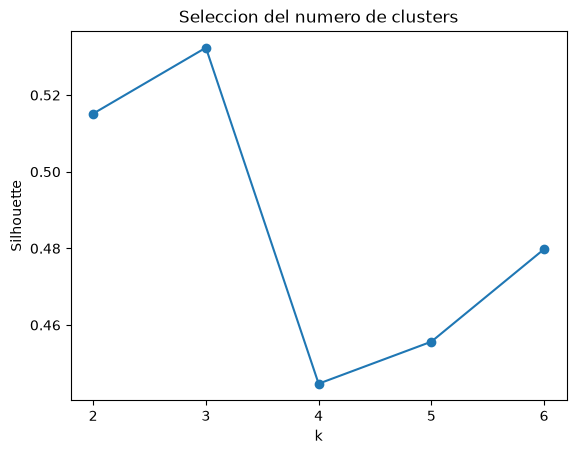

In [64]:
fila_max_k = resultados[resultados["silhouette"] == resultados["silhouette"].max()]
k_elegido = fila_max_k["k"].values[0]
modelo = modelos[k_elegido]
etiquetas = modelo.labels_
print(f"Se elige k={k_elegido}: mayor Silhouette entre los valores evaluados.")
resultados.plot(x="k", y="silhouette", marker="o", legend=False)

plt.xticks(resultados["k"])
plt.ylabel("Silhouette")
plt.title("Seleccion del numero de clusters")
plt.show()

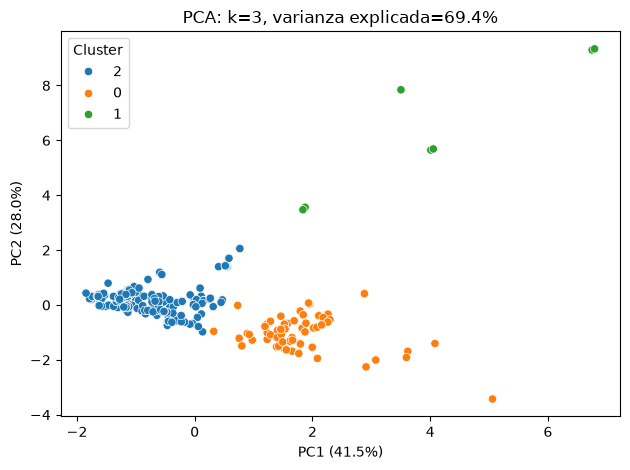

In [65]:
pca = PCA(n_components=2)
proyeccion = pca.fit_transform(X_escalado)
varianza = pca.explained_variance_ratio_ * 100
sns.scatterplot(x=proyeccion[:, 0], y=proyeccion[:, 1], hue=etiquetas.astype(str))
plt.xlabel(f"PC1 ({varianza[0]:.1f}%)")
plt.ylabel(f"PC2 ({varianza[1]:.1f}%)")
plt.title(f"PCA: k={k_elegido}, varianza explicada={varianza.sum():.1f}%")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

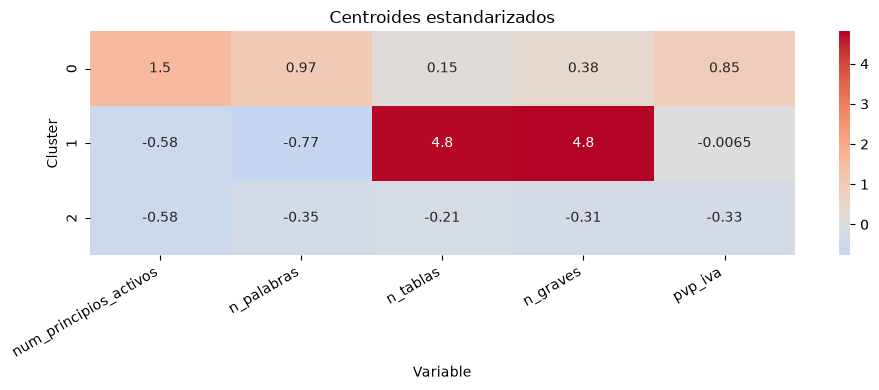

In [66]:
centroides = pd.DataFrame(modelo.cluster_centers_, columns=variables)
plt.figure(figsize=(10, 4))
sns.heatmap(centroides, annot=True, cmap="coolwarm", center=0)
plt.xlabel("Variable")
plt.ylabel("Cluster")
plt.title("Centroides estandarizados")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [67]:
df["cluster"] = etiquetas
grupos = df.groupby("cluster")
resumen = grupos[variables].mean()
resumen["tamaño"] = grupos.size()
resumen.round(2)

,num_principios_activos,n_palabras,n_tablas,n_graves,pvp_iva,tamaño
cluster,,,,,,
0,2.0,1448.78,3.74,14.99,39.79,108
1,1.0,570.44,26.22,66.67,22.13,9
2,1.0,782.35,1.98,7.02,15.38,275


Interpretación descriptiva de los grupos (medias en las unidades originales):

- **Cluster 0: dos principios activos y mayor precio medio** (108 filas). Tiene 2 principios activos, unas 1449 palabras y un precio medio de 39,79.
- **Cluster 1: mayor numero de tablas y mayor n_graves** (9 filas). Destaca por unas 26,22 tablas y un valor medio de n_graves de 66,67. Es un grupo pequeño que conviene interpretar con cautela.
- **Cluster 2: un principio activo y menor precio medio** (275 filas). Tiene 1 principio activo, unas 782 palabras y un precio medio de 15,38.

Estos nombres describen los datos. No representan categorías clínicas. El mapa de calor compara cada centro con la media global en unidades de desviación típica. El PCA solo sirve para visualizar en 2 dimensiones. K-Means y Silhouette utilizan las cinco variables escaladas.

In [68]:
# CSV con los datos limpios
df_salida = df.copy()
df_salida["cluster"] = etiquetas
df_salida.to_csv(ruta / "datos_clusters.csv", index=False)

# CSV con los datos completos
completos = pd.read_csv(ruta / "datos_completos.csv")
completos["cluster"] = etiquetas
completos.to_csv(ruta / "datos_completos_clusters.csv", index=False)